# Generate some prediction on validation images using the binary_classification_model

In [8]:
import os
import sys
import pandas as pd
import matplotlib.pylab as plt
import torch

PROJECT_ROOT = os.path.abspath(".")
if not os.path.exists(os.path.join(PROJECT_ROOT, "config", "binary_model_v4_synaptic_hcs.yml")):
    PROJECT_ROOT = os.path.abspath("MONAI-test")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.config import load_yaml_config

CONFIG_PATHS = [
   # os.path.join(PROJECT_ROOT, "config", "binary_model_v1.yml"),
  #  os.path.join(PROJECT_ROOT, "config", "binary_model_v2.yml"),
    os.path.join(PROJECT_ROOT, "config", "binary_model_v4_synaptic_hcs.yml"),
#    os.path.join(PROJECT_ROOT, "config", "binary_model_v5_synaptic_sgn+haircells.yml"),# Can't compare with v4 because it uses a different dataset, so the results are not comparable
]

model_runs = []
for config_path in CONFIG_PATHS[:3]:
    model_runs.append({
        "name": os.path.splitext(os.path.basename(config_path))[0],
        "config_path": config_path,
        "config": load_yaml_config(config_path),
    })

config = model_runs[0]["config"]
data_config = config["data"]
augmentation_config = config["augmentation"]
training_config = config["training"]
validation_config = config["validation"]


def resolve_project_path(path):
    if os.path.isabs(path):
        return path
    return os.path.join(PROJECT_ROOT, path)


patch_size = tuple(data_config["patch_size"])
data_dir = resolve_project_path(data_config["data_dir"])
split_file = resolve_project_path(data_config["split_file"])


In [9]:
from src import data, transforms

excel_folder = resolve_project_path(data_config["excel_folder"])
alldata = data.load_all_excels(folder=excel_folder, drive=data_config["drive"],        
                    exclusions=None if data_config.get("exclusions", None) == "None" else data_config.get("exclusions", None),
                    inclusions = None if data_config.get("inclusions", None) == "None" else data_config.get("inclusions", None))

dfdata = data.generate_dataset(
    alldata,
    copy_type=data_config["copy_type"],
    overwrite=data_config["overwrite"],
    local_data_folder=data_dir,
    require_annotations=data_config.get("require_annotations", True)

)


 26%|██▌       | 72/277 [00:00<00:00, 228.02it/s]

Avg file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_03_31_NeuroD-GCaMP6f_P4_in vivo/1/processedMovies/Avg.tif
Avg file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_04_04_NeuroD-GCaMP6f_P8_in vivo/1/processedMovies/Avg.tif
Avg file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_06_09_NeuroD-GCaMP6f_P8_in vivo/1/processedMovies/Avg.tif


 54%|█████▍    | 150/277 [00:00<00:00, 249.93it/s]

Avg file does not exist: /Volumes/data/Users/Francesca/Data/2025/2025_04_28_NeuroD-GCaMP6f_P7_in vivo_injectable anaesthetic/3/processedMovies/Avg.tif
Avg file does not exist: /Volumes/data/Users/Francesca/Data/2025/2025_04_28_NeuroD-GCaMP6f_P7_in vivo_injectable anaesthetic/3_001/processedMovies/Avg.tif
Avg file does not exist: /Volumes/data/Users/Francesca/Data/2025/2025_04_28_NeuroD-GCaMP6f_P7_in vivo_injectable anaesthetic/3_002/processedMovies/Avg.tif
Avg file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_02_27_NeuroD-Cre-GCaMP6f_P6_in vivo/9/processedMovies/Avg.tif
Avg file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_02_27_NeuroD-Cre-GCaMP6f_P6_in vivo/10/processedMovies/Avg.tif
Avg file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_03_03_NeuroD-Cre-GCaMP6f_P4_in vivo/5/processedMovies/Avg.tif
Avg file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_03_03_NeuroD-Cre-GCaMP6f_P4_in vivo/6/processedMovies/Avg.tif
Avg file d

 78%|███████▊  | 216/277 [00:00<00:00, 291.80it/s]

Avg file does not exist: /Volumes/data/Users/Francesca/Data/2023/2023_06_29_SNAP25-GCaMP6s_P4_in vivo/3/processedMovies/Avg.tif
Avg file does not exist: E:/Users/Federico/Data/2024/InVivoProject/20240910-SNAP25-RT-GCampExplant/1-RT/processedMovies/Avg.tif
Avg file does not exist: E:/Users/Federico/Data/2024/InVivoProject/20240910-SNAP25-RT-GCampExplant/2-RT/processedMovies/Avg.tif
Avg file does not exist: E:/Users/Federico/Data/2024/InVivoProject/20240911-SNAP25-RT-GCampExplant/1-P9-RT/processedMovies/Avg.tif
Avg file does not exist: E:/Users/Federico/Data/2024/InVivoProject/20240911-SNAP25-RT-GCampExplant/2-P9-RT/processedMovies/Avg.tif
Avg file does not exist: E:/Users/Federico/Data/2024/InVivoProject/20240911-SNAP25-RT-GCampExplant/3-P9-RT_001/processedMovies/Avg.tif
Avg file does not exist: E:/Users/Federico/Data/2024/InVivoProject/20240911-SNAP25-RT-GCampExplant/3-P9-RT_002/processedMovies/Avg.tif
Avg file does not exist: E:/Users/Federico/Data/2024/InVivoProject/20240911-SNAP25-R

100%|██████████| 277/277 [00:01<00:00, 256.14it/s]


## 1. Load the train/test split from the json file

In [10]:
train_data, val_data = data.train_test_split(
    dfdata,
    column=data_config["column"],
    test_size=data_config["test_size"],
    random_state=data_config["random_state"],
    split_json_path=split_file,
    save_split_json=data_config["save_split_json"],
    data_dir=data_dir,
    require_annotations=data_config.get("require_annotations", True)
)


## 2. Load the transformations on train and val (val does not have data augmentations)

In [11]:
train_transforms, val_transforms = transforms.get_transforms_binary_classification(
    num_samples=data_config["num_samples"],
    spatial_size=patch_size,
    pos=data_config["pos"],
    neg=data_config["neg"],
    filter_by_annotation=data_config.get("require_annotations", True),
    annotation_indices=data_config["annotation_indices"],
    flip_vertical=augmentation_config["flip_vertical"],
    flip_vertical_prob=augmentation_config["flip_vertical_prob"],
    flip_horizontal=augmentation_config["flip_horizontal"],
    flip_horizontal_prob=augmentation_config["flip_horizontal_prob"],
    rotate90=augmentation_config["rotate90"],
    rotate90_prob=augmentation_config["rotate90_prob"],
    rotate90_max_k=augmentation_config["rotate90_max_k"],
    intensity_scale=augmentation_config["intensity_scale"],
    intensity_scale_prob=augmentation_config["intensity_scale_prob"],
    intensity_scale_factors=augmentation_config["intensity_scale_factors"],
    intensity_shift=augmentation_config["intensity_shift"],
    intensity_shift_prob=augmentation_config["intensity_shift_prob"],
    intensity_shift_offsets=augmentation_config["intensity_shift_offsets"],
)


## 3. Create datasets and dataloaders

In [12]:
# Create dataset and dataloader
train_ds, train_loader, val_ds, val_loader = data.create_datasets_and_loaders(
    train_data,
    val_data,
    train_transforms,
    val_transforms,
    batch_size=training_config["batch_size"],
    val_batch_size=training_config["val_batch_size"],
    num_workers=training_config["num_workers"],
    shuffle_train=training_config["shuffle_train"],
    shuffle_val=training_config["shuffle_val"],
)

# define torch device
configured_device = training_config["device"]
if configured_device == "auto":
    if torch.cuda.is_available():
        device = torch.device("cuda")
    elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        device = torch.device("mps")
    else:
        device = torch.device("cpu")
else:
    device = torch.device(configured_device)
print("Using device:", device)


Using device: mps


## 4. Define the model and various training metrics and postprocessing

In [13]:
# Load models
from src.model import build_binary_model

for run in model_runs:
    model_config = run["config"]["model"]
    model = build_binary_model(
        architecture=model_config["architecture"],
        spatial_dims=model_config["spatial_dims"],
        in_channels=model_config["in_channels"],
        out_channels=model_config["out_channels"],
        channels=model_config["channels"],
        strides=model_config["strides"],
        num_res_units=model_config["num_res_units"],
    ).to(device)

    checkpoint_path = resolve_project_path(model_config["best_model_path"])
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    run["model"] = model
    run["checkpoint_path"] = checkpoint_path
    print(f"Loaded {run['name']}: {checkpoint_path}")


Loaded binary_model_v4_synaptic_hcs: /Users/federico/Documents/git-repos/cochlea-hair-cell-binary-segmentation-unet2d/checkpoints/best_model_binary_v4_synaptic_hcs.pth


/Users/federico/Documents/git-repos/cochlea-hair-cell-binary-segmentation-unet2d/.venv/lib/python3.9/site-packages/monai/inferers/utils.py:226: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/python_variable_indexing.cpp:312.)
  win_data = torch.cat([inputs[win_slice] for win_slice in unravel_slice]).to(sw_device)
/Users/federico/Documents/git-repos/cochlea-hair-cell-binary-segmentation-unet2d/.venv/lib/python3.9/site-packages/monai/inferers/utils.py:370: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tenso

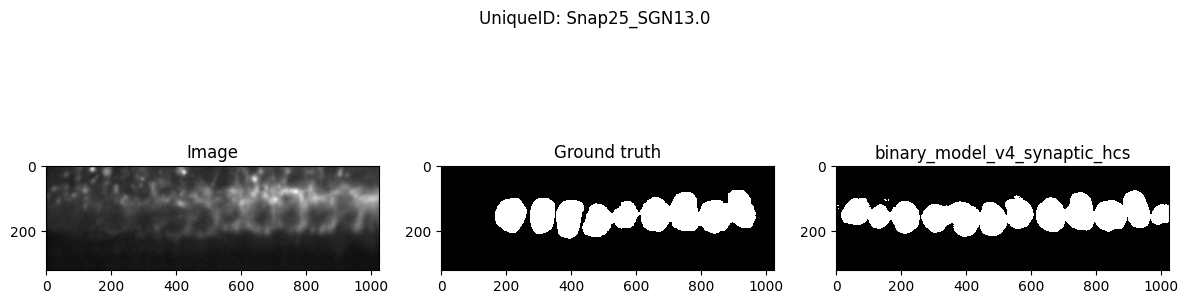

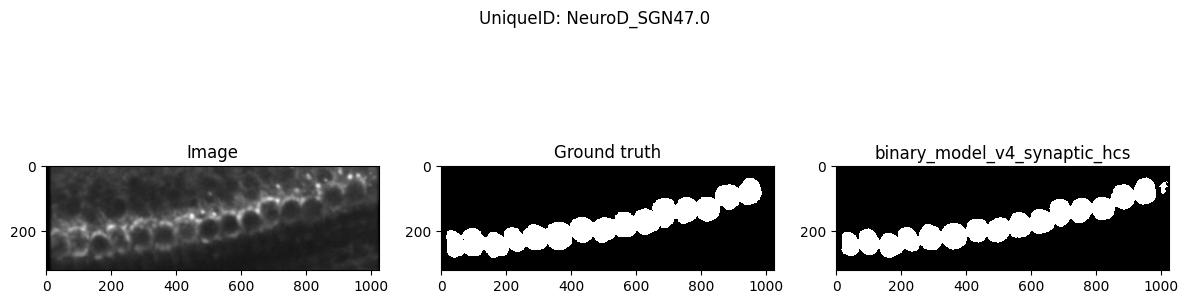

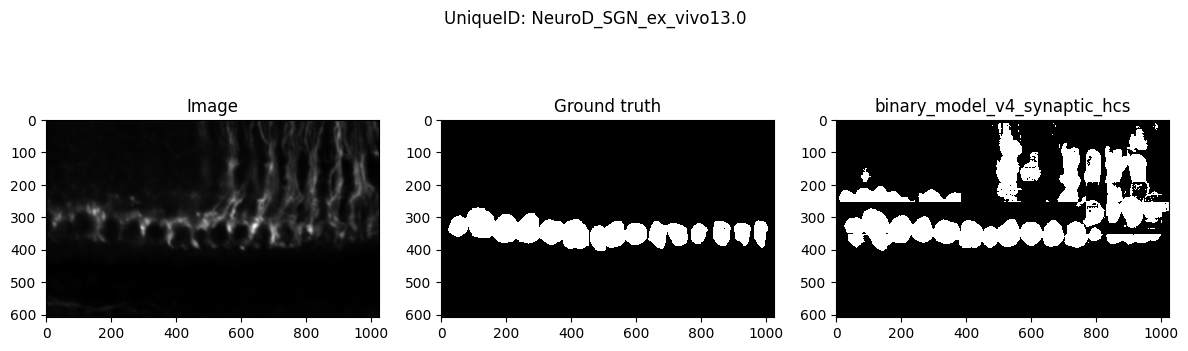

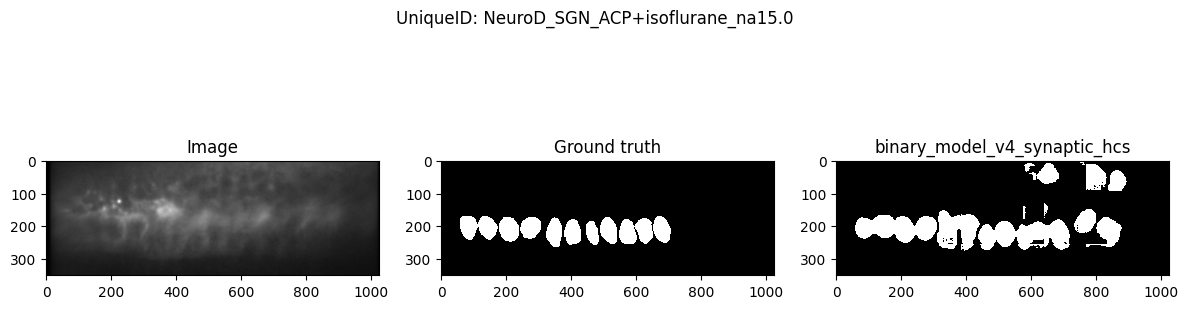

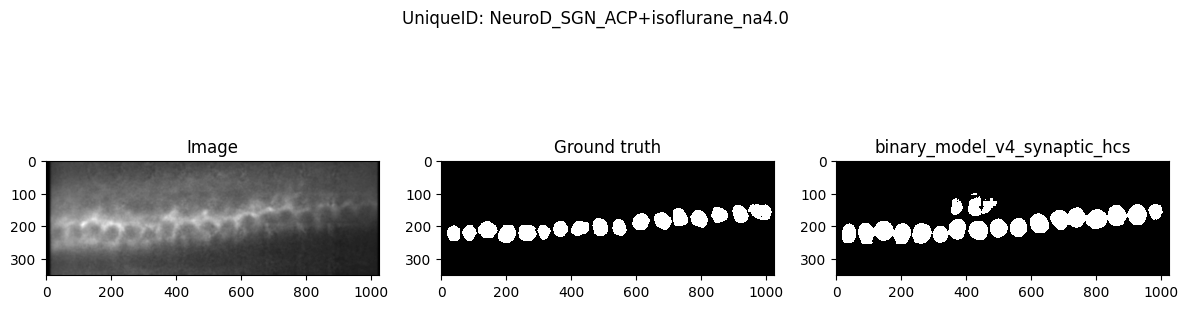

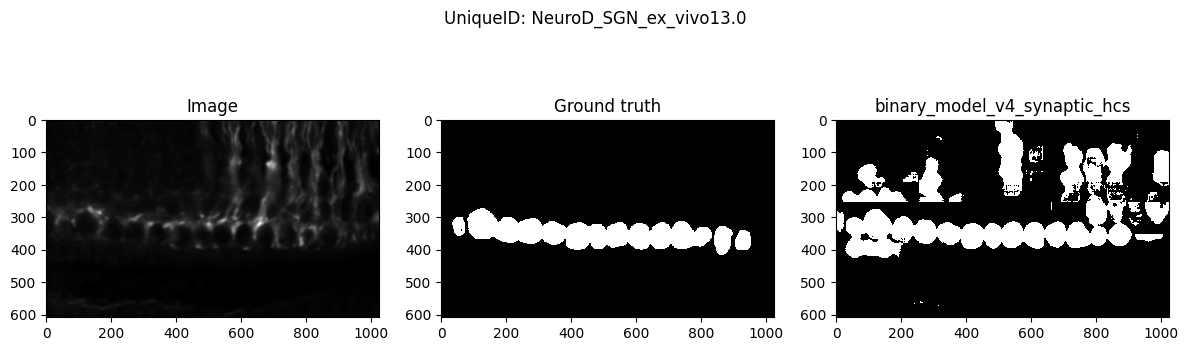

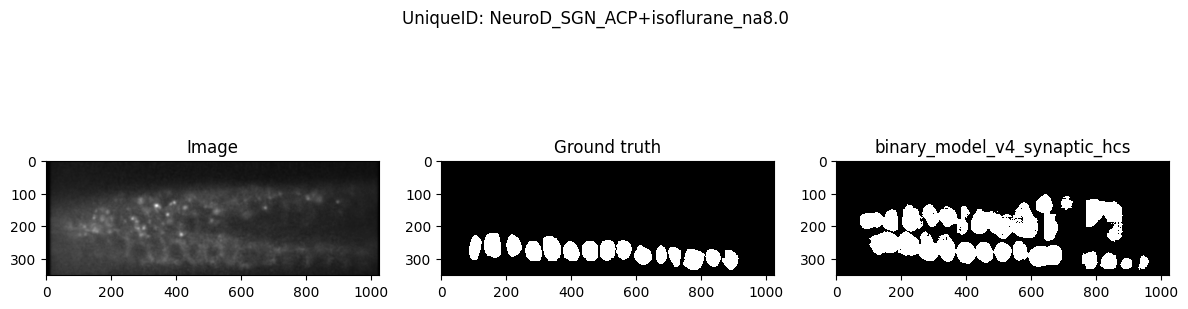

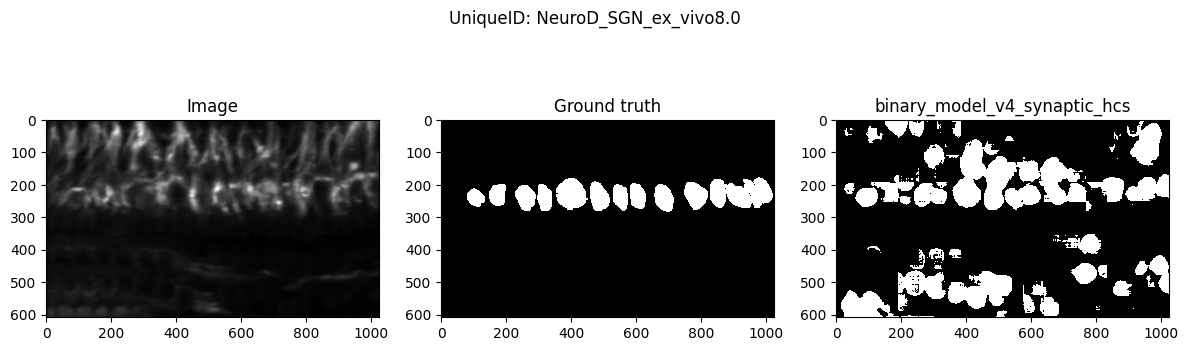

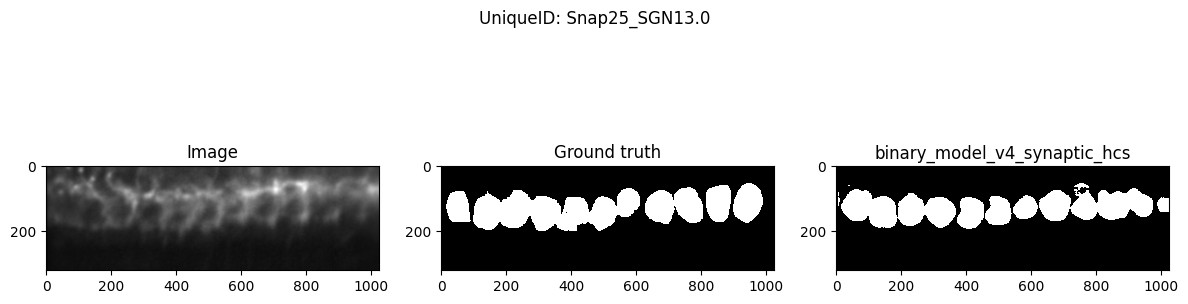

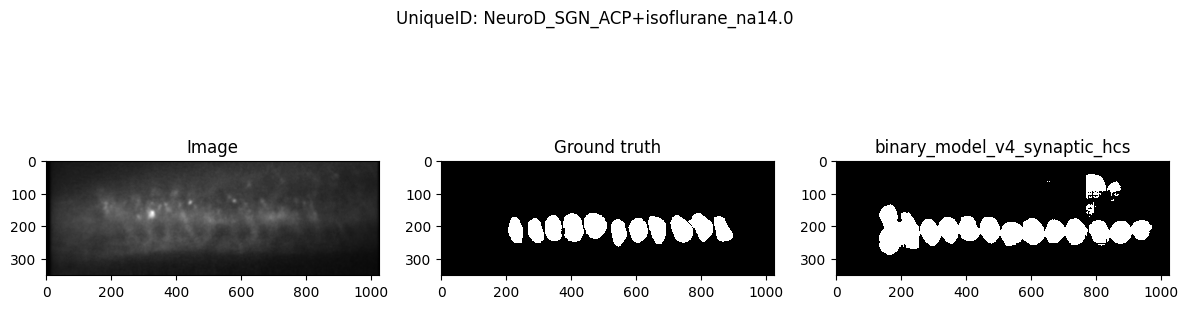

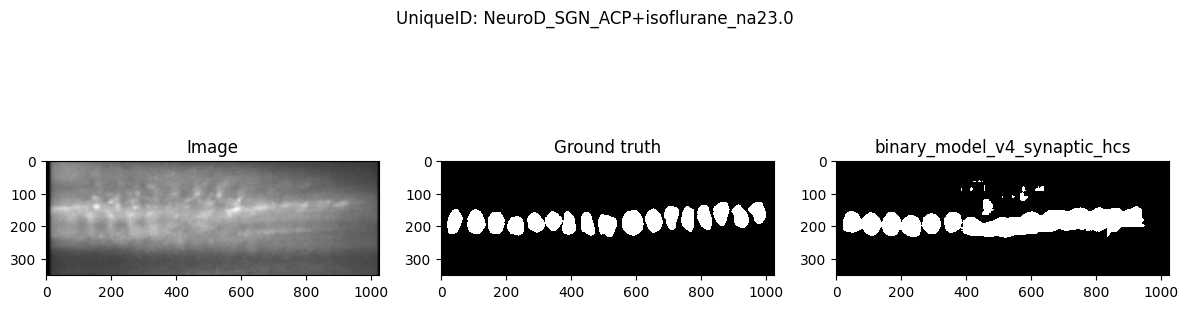

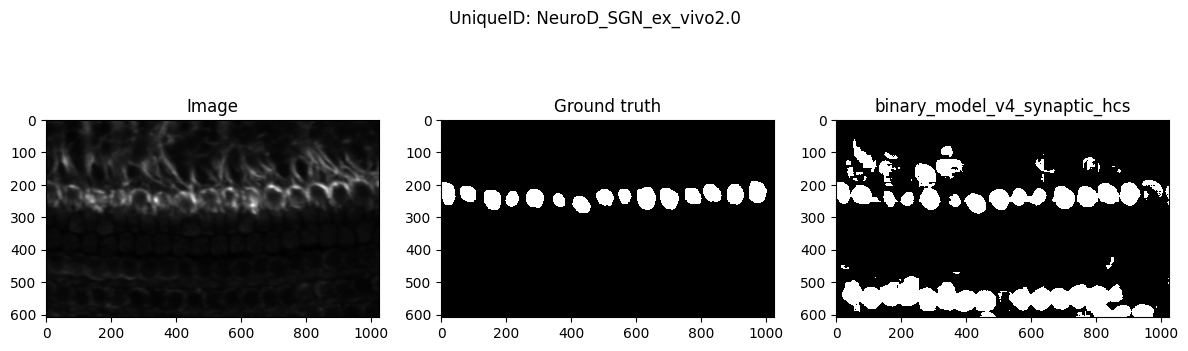

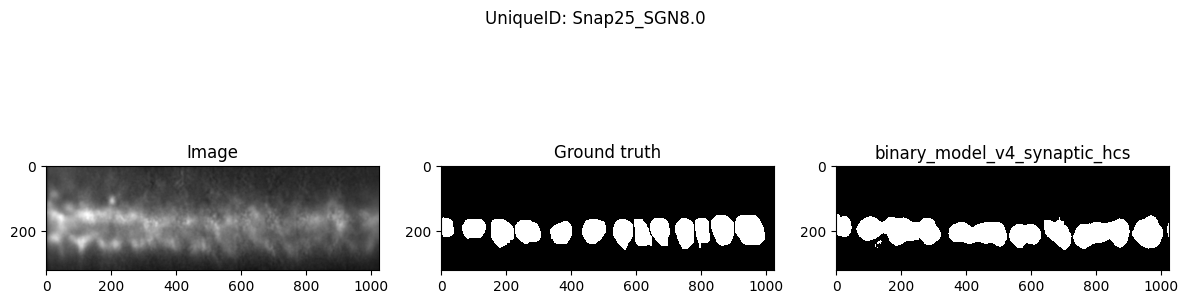

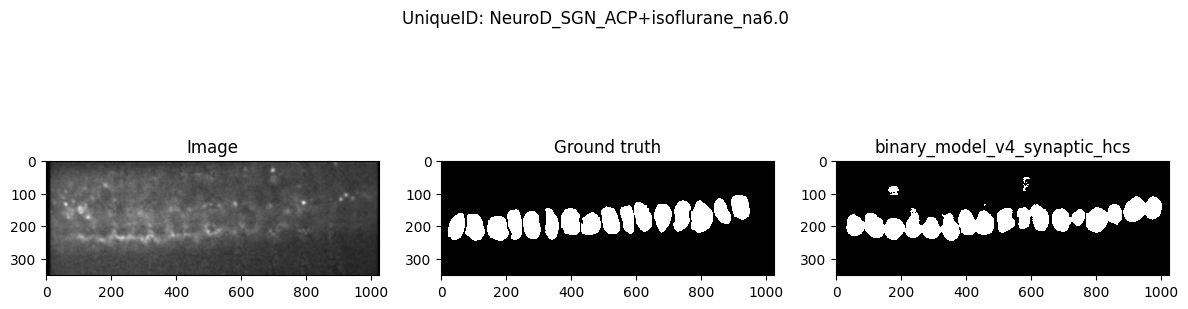

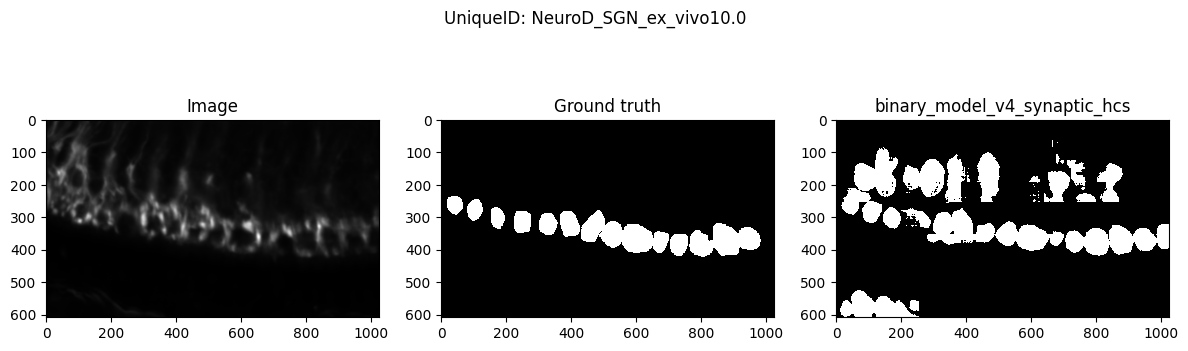

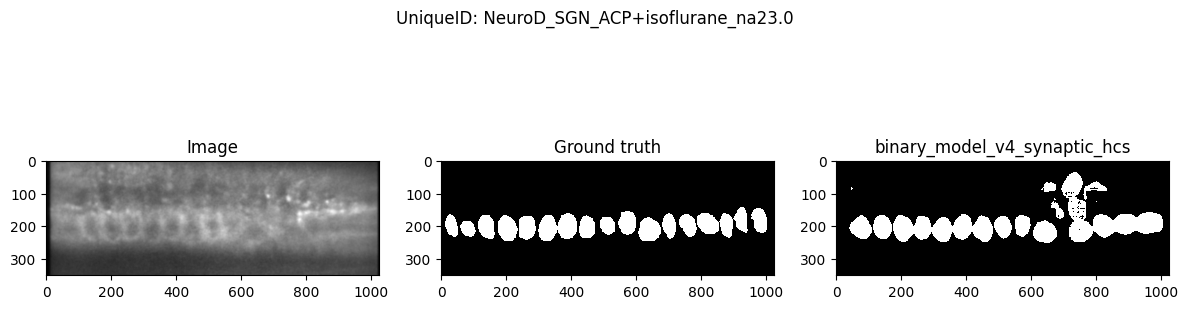

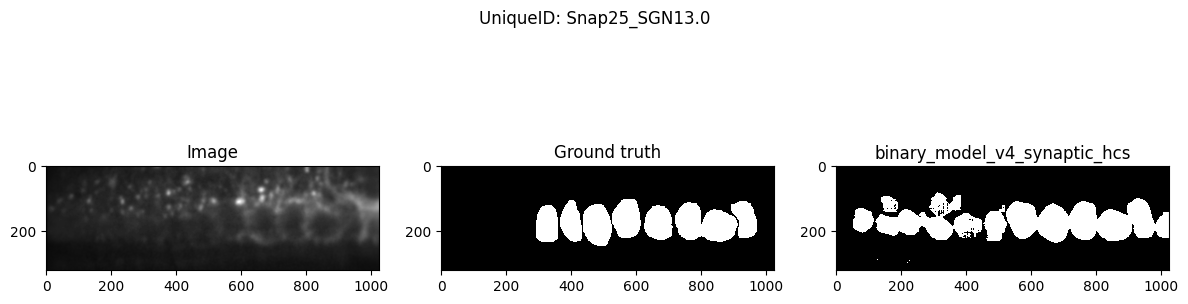

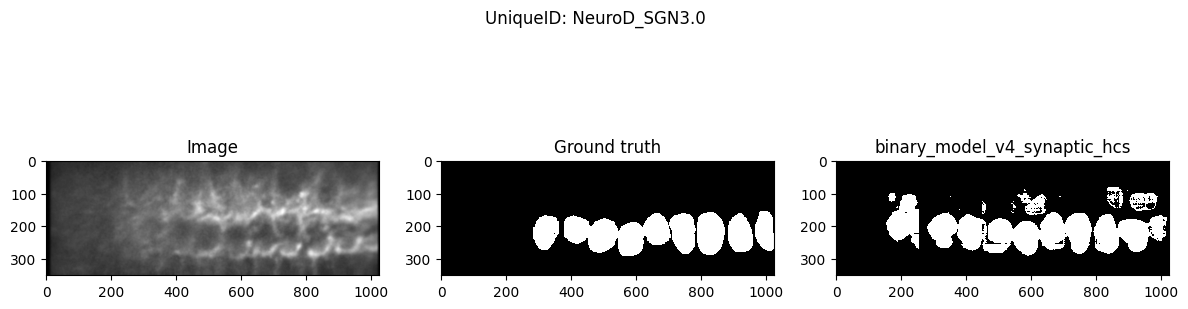

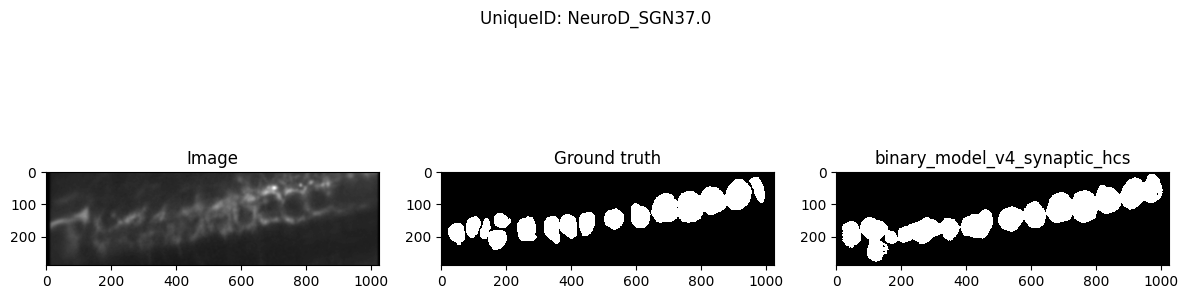

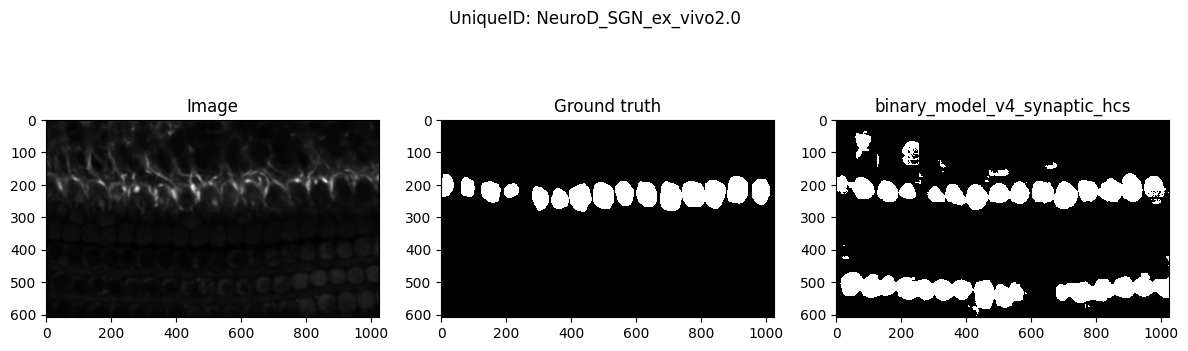

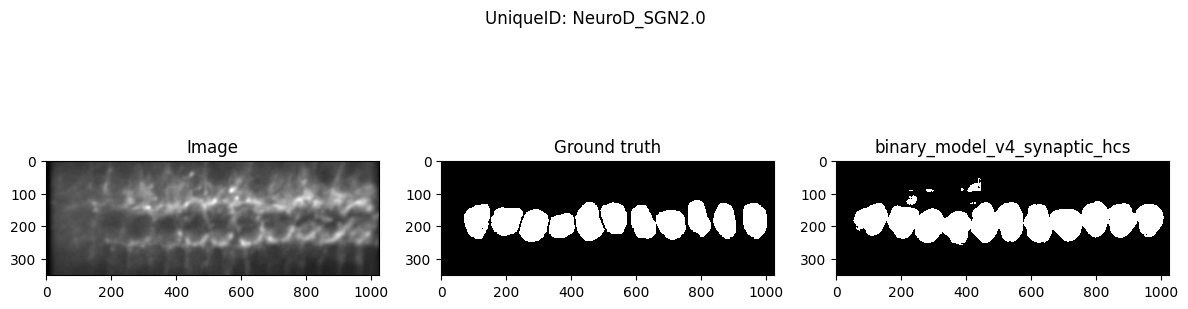

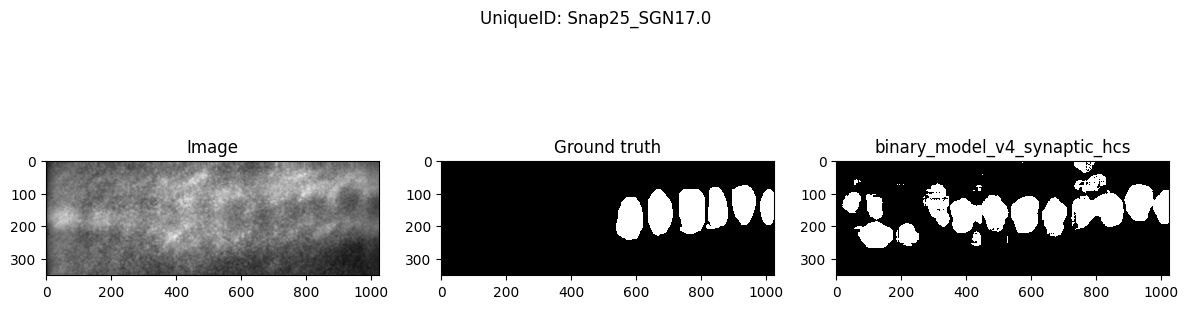

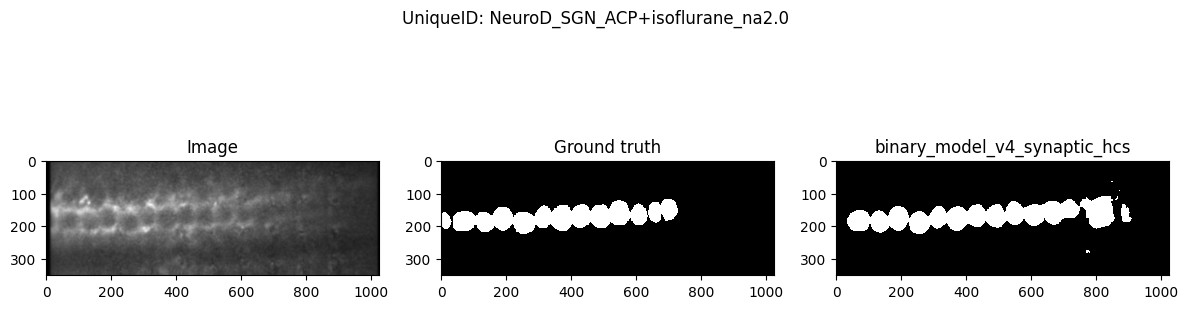

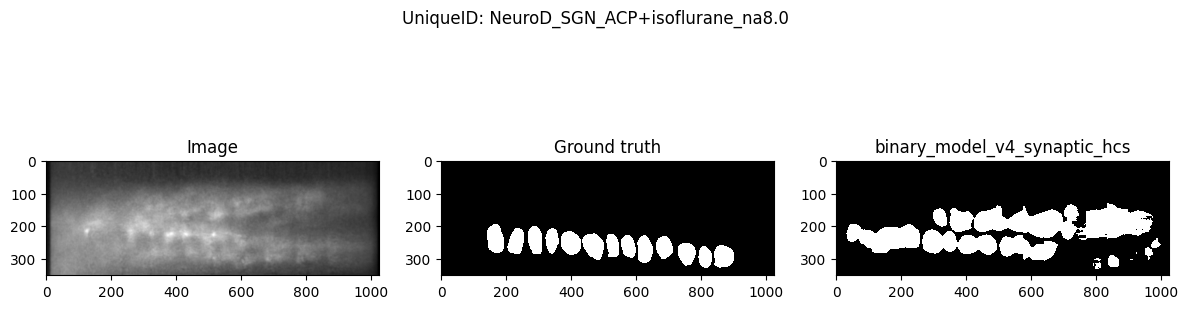

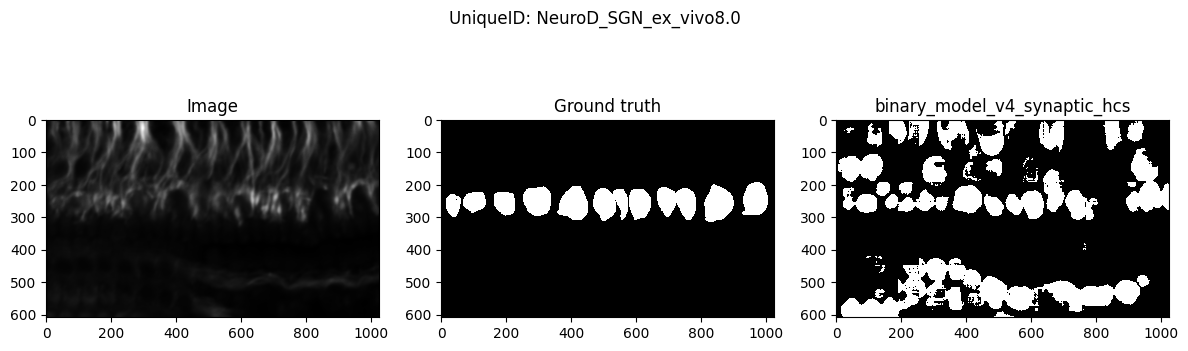

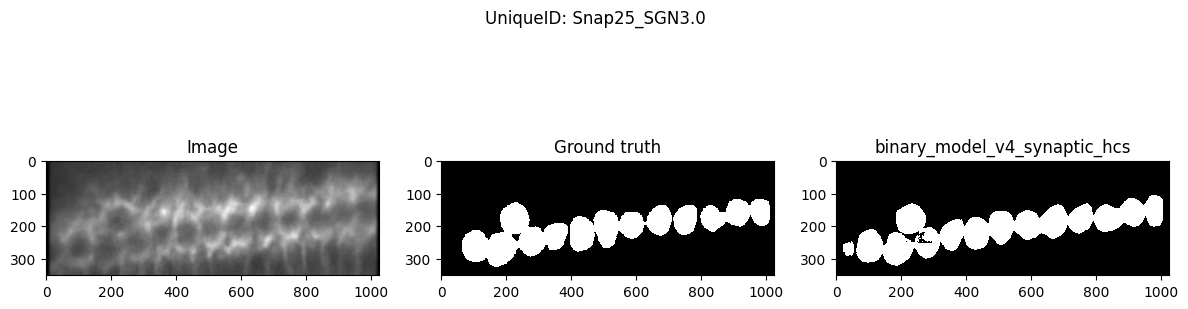

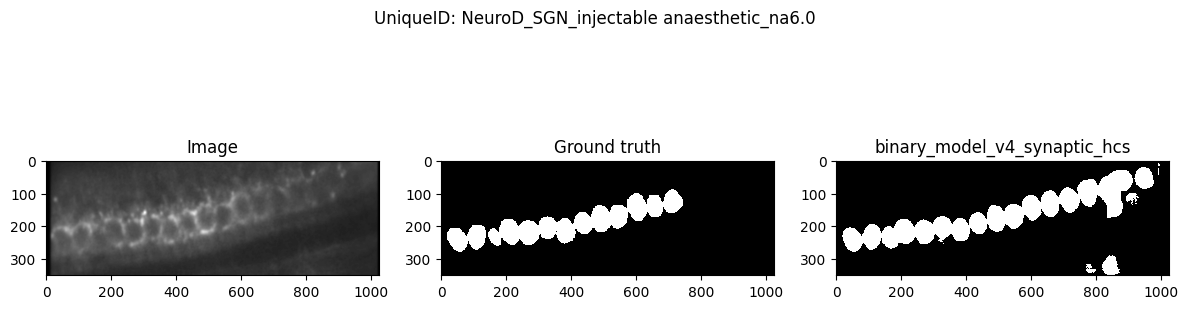

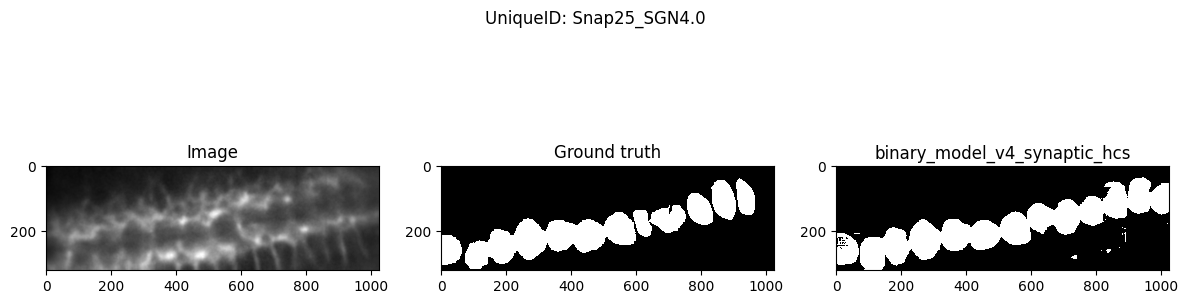

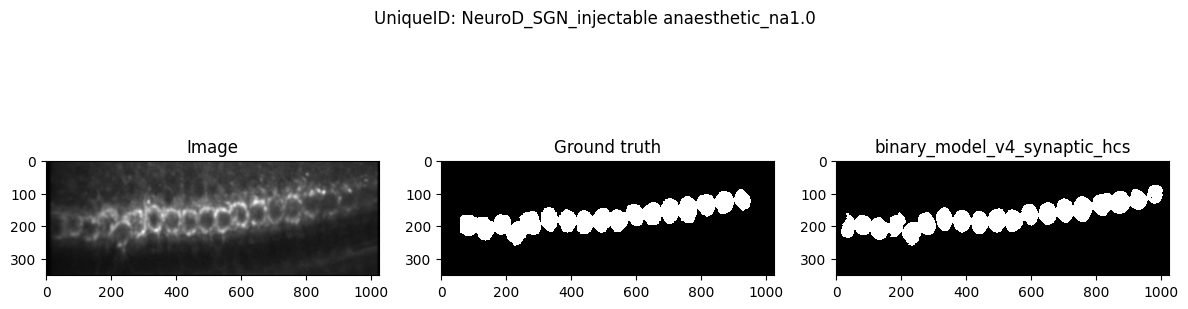

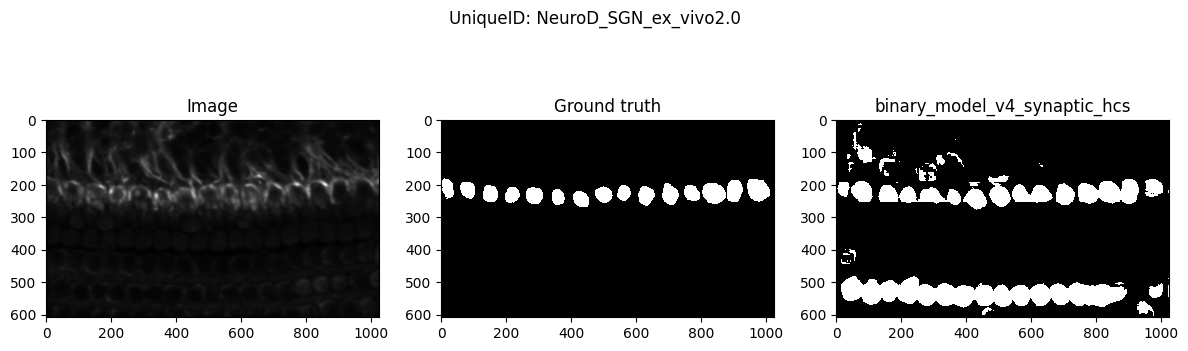

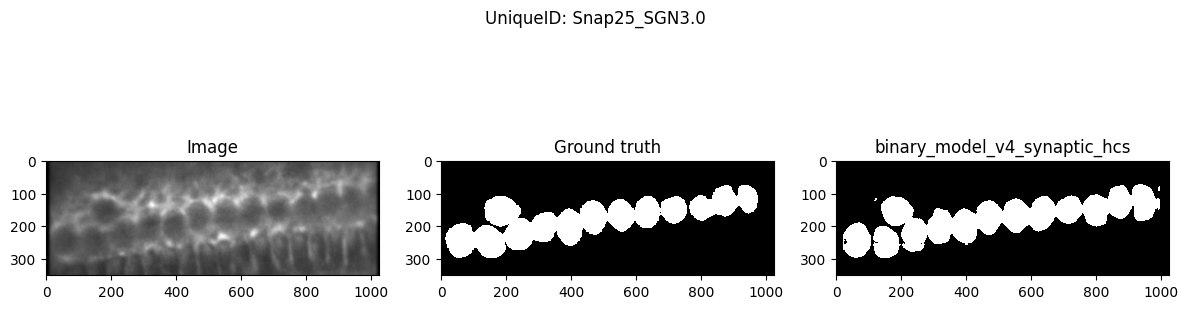

In [14]:
# Imshow the predictions for a few validation images
import matplotlib.pyplot as plt
from src import inference
import tifffile
import numpy as np

with torch.no_grad():
    for i, batch in enumerate(val_loader):
        image = batch["image"].to(device)
        label = batch["label"].to(device)
        uniqueid = batch[data_config["column"]][0]

        gt = label

        ncols = 2 + len(model_runs)
        plt.figure(figsize=(4 * ncols, 4))

        plt.subplot(1, ncols, 1)
        plt.imshow(image[0, 0].cpu(), cmap="gray")
        plt.title("Image")

        plt.subplot(1, ncols, 2)
        #plt.imshow(gt[0, 0].cpu(), cmap="gray")
        plt.imshow(label[0, 0].cpu(), cmap="gray", interpolation="none")
        plt.title("Ground truth")

        for col, run in enumerate(model_runs, start=3):
            run_validation_config = run["config"]["validation"]
            pred = inference.predict_binary(
                run["model"],
                image,
                device,
                roi_size=tuple(run_validation_config["roi_size"]),
                sw_batch_size=run_validation_config["sw_batch_size"],
                prediction_sigmoid=run_validation_config["prediction_sigmoid"],
                prediction_threshold=run_validation_config["prediction_threshold"],
            )
            binary_labels = np.array(pred.cpu()[0][0]).astype(np.uint32)
            plt.subplot(1, ncols, col)
            plt.imshow(binary_labels, cmap='gray', interpolation="none")
            plt.title(run["name"])

        plt.suptitle(f"UniqueID: {uniqueid}")
        plt.tight_layout()
        plt.show()

        if i >= 30:
            break
